# 01. Preparación de datos y análisis exploratorio

Se construye el conjunto de datos a nivel de pedido y se caracteriza la insatisfacción de los clientes mediante análisis descriptivo (¿qué ocurrió?) y diagnóstico (¿por qué ocurrió?). Las conclusiones de este cuaderno orientan las decisiones de modelado de los cuadernos 02 y 03.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.datos import cargar_pedidos, VARIABLES_PEDIDO
from src.graficos import configurar_estilo, guardar, AZUL, NARANJA, GRIS

configurar_estilo()
RUTA_DATOS = "../data/raw"

## 1. Conjunto de datos

El dataset de Olist contiene cerca de 99 mil pedidos (2016-2018) distribuidos en nueve tablas. La función `cargar_pedidos` (`src/datos.py`) une pedidos, reseñas, ítems, productos, pagos, clientes, vendedores y geolocalización, y deja una fila por pedido con reseña. Las fechas se transforman en duraciones en días y la distancia entre vendedor y cliente se calcula con la fórmula de haversine.

In [2]:
df = cargar_pedidos(RUTA_DATOS)
print(f"Pedidos con reseña: {len(df):,}")
df[VARIABLES_PEDIDO].describe().T.round(2)

Pedidos con reseña: 98,673


,count,mean,std,min,25%,50%,75%,max
entregado,98673.0,0.97,0.17,0.00,1.00,1.00,1.00,1.00
dias_entrega_real,95830.0,12.52,9.46,0.53,6.76,10.21,15.66,208.35
dias_entrega_estimada,98673.0,23.76,8.83,1.65,18.33,23.24,28.42,155.14
dias_retraso,95830.0,-11.22,10.12,-146.02,-16.25,-11.97,-6.41,188.98
dias_despacho_vs_limite,96926.0,-3.36,6.06,-1054.24,-5.22,-3.23,-1.58,116.76
n_items,97917.0,1.14,0.53,1.00,1.00,1.00,1.00,21.00
n_vendedores,97917.0,1.01,0.12,1.00,1.00,1.00,1.00,5.00
precio_total,97917.0,137.53,209.48,0.85,45.90,86.90,149.90,13440.00
flete_total,97917.0,22.80,21.62,0.00,13.84,17.16,24.01,1794.96
peso_total_g,97917.0,2386.69,4770.70,0.00,300.00,750.00,2050.00,184400.00


In [3]:
faltantes = df[VARIABLES_PEDIDO].isna().mean().mul(100).round(2)
faltantes[faltantes > 0].sort_values(ascending=False).rename("% faltante")

dias_entrega_real          2.88
dias_retraso               2.88
fotos_prom                 2.16
dias_despacho_vs_limite    1.77
distancia_km               1.26
n_items                    0.77
precio_total               0.77
n_vendedores               0.77
peso_total_g               0.77
flete_total                0.77
Name: % faltante, dtype: float64

Los faltantes de las variables de entrega corresponden a pedidos que no llegaron al cliente, por lo que no tienen fecha de entrega. En el cuaderno 02 se imputan con la mediana del conjunto de entrenamiento; la variable `entregado` conserva la información de que el pedido no llegó.

## 2. Variable objetivo

Se define `insatisfecho = 1` si la reseña tiene entre 1 y 3 estrellas y `0` si tiene 4 o 5. La calificación de 3 se agrupa con las negativas porque no corresponde a un cliente satisfecho y, desde el punto de vista del servicio, también requiere atención.

Proporción de insatisfechos: 22.9%


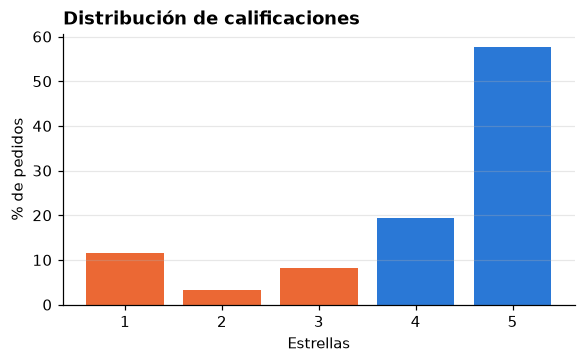

In [4]:
estrellas = df["review_score"].value_counts().sort_index()
print(f"Proporción de insatisfechos: {df['insatisfecho'].mean():.1%}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(estrellas.index.astype(str), estrellas.values / len(df) * 100,
       color=[NARANJA] * 3 + [AZUL] * 2)
ax.set_xlabel("Estrellas")
ax.set_ylabel("% de pedidos")
ax.set_title("Distribución de calificaciones")
guardar(fig, "distribucion_estrellas")
plt.show()

## 3. Análisis descriptivo

### 3.1 Evolución mensual

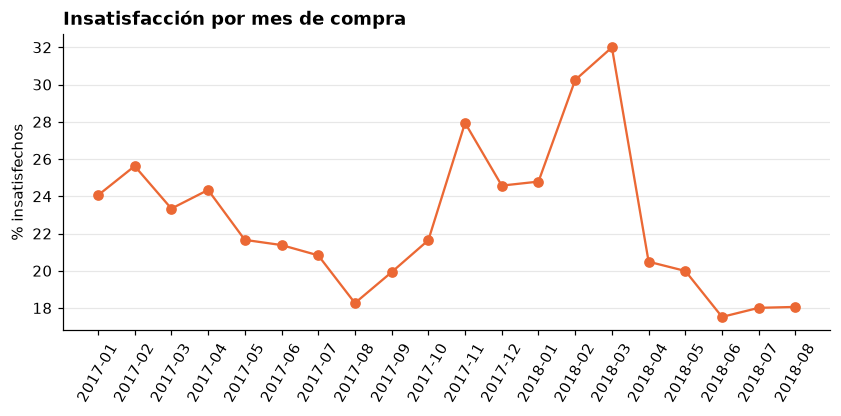

In [5]:
mensual = (df.groupby("mes_compra")
             .agg(pedidos=("order_id", "size"),
                  insatisfechos=("insatisfecho", "mean"),
                  tarde=("estado_entrega", lambda s: (s == "Tarde").mean()))
             .query("pedidos >= 500"))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(mensual.index, mensual["insatisfechos"] * 100, marker="o", color=NARANJA)
ax.set_ylabel("% insatisfechos")
ax.set_title("Insatisfacción por mes de compra")
ax.tick_params(axis="x", rotation=60)
plt.show()

### 3.2 Categoría de producto y estado del cliente

In [6]:
por_categoria = (df.groupby("categoria")
                   .agg(pedidos=("order_id", "size"), insatisfechos=("insatisfecho", "mean"))
                   .query("pedidos >= 1000")
                   .sort_values("insatisfechos", ascending=False))
por_categoria.assign(insatisfechos=lambda x: (x["insatisfechos"] * 100).round(1)).head(10)

,pedidos,insatisfechos
categoria,,
office_furniture,1255,36.9
bed_bath_table,9211,26.5
telephony,4151,25.4
furniture_decor,6305,25.1
consoles_games,1048,24.2
computers_accessories,6621,24.2
baby,2815,24.2
watches_gifts,5554,23.6
auto,3861,22.1


In [7]:
por_estado = (df.groupby("customer_state")
                .agg(pedidos=("order_id", "size"), insatisfechos=("insatisfecho", "mean"))
                .query("pedidos >= 1000")
                .sort_values("insatisfechos", ascending=False))
por_estado.assign(insatisfechos=lambda x: (x["insatisfechos"] * 100).round(1))

,pedidos,insatisfechos
customer_state,,
CE,1326,29.6
BA,3340,28.9
RJ,12687,28.9
PE,1635,24.7
GO,2007,24.2
ES,2006,24.0
SC,3609,23.5
DF,2128,22.9
MG,11554,21.6


### 3.3 Comentarios

In [8]:
print(f"Pedidos con comentario: {df['tiene_comentario'].mean():.1%}")
df.groupby("insatisfecho")["tiene_comentario"].mean().rename({0: "satisfechos", 1: "insatisfechos"}).round(3)

Pedidos con comentario: 41.3%


insatisfecho
satisfechos      0.347
insatisfechos    0.635
Name: tiene_comentario, dtype: float64

**Resumen descriptivo.** El 22,9 % de los clientes queda insatisfecho. La proporción aumenta en noviembre de 2017 y en febrero-marzo de 2018, es mayor en muebles de oficina y en los estados del nordeste y Río de Janeiro, y menor en São Paulo. Los insatisfechos dejan comentario con casi el doble de frecuencia que los satisfechos (63,5 % frente a 34,7 %).

## 4. Análisis diagnóstico

### 4.1 Cumplimiento de la entrega

In [9]:
(df.groupby("estado_entrega")
   .agg(pedidos=("order_id", "size"),
        pct_insatisfechos=("insatisfecho", "mean"),
        estrellas_promedio=("review_score", "mean"))
   .assign(pct_insatisfechos=lambda x: (x["pct_insatisfechos"] * 100).round(1))
   .round(2))

,pedidos,pct_insatisfechos,estrellas_promedio
estado_entrega,,,
A tiempo,88163,17.2,4.29
No entregado,2849,85.6,1.75
Tarde,7661,65.4,2.57


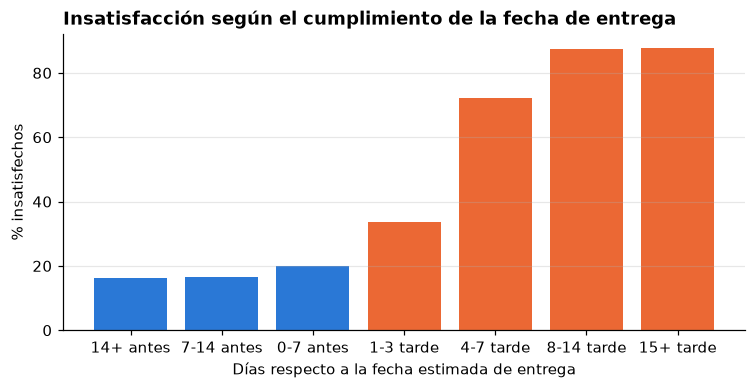

,size,mean
tramo,,
14+ antes,34771,0.164
7-14 antes,36158,0.166
0-7 antes,17234,0.201
1-3 tarde,2636,0.337
4-7 tarde,1773,0.721
8-14 tarde,1748,0.873
15+ tarde,1504,0.878


In [10]:
entregados = df[df["estado_entrega"] != "No entregado"].copy()
cortes = [-np.inf, -14, -7, 0, 3, 7, 14, np.inf]
tramos = ["14+ antes", "7-14 antes", "0-7 antes", "1-3 tarde", "4-7 tarde", "8-14 tarde", "15+ tarde"]
entregados["tramo"] = pd.cut(entregados["dias_retraso"], bins=cortes, labels=tramos)
por_tramo = entregados.groupby("tramo", observed=True)["insatisfecho"].agg(["size", "mean"])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(por_tramo.index.astype(str), por_tramo["mean"] * 100, color=[AZUL] * 3 + [NARANJA] * 4)
ax.set_ylabel("% insatisfechos")
ax.set_xlabel("Días respecto a la fecha estimada de entrega")
ax.set_title("Insatisfacción según el cumplimiento de la fecha de entrega")
guardar(fig, "insatisfaccion_retraso")
plt.show()
por_tramo.round(3)

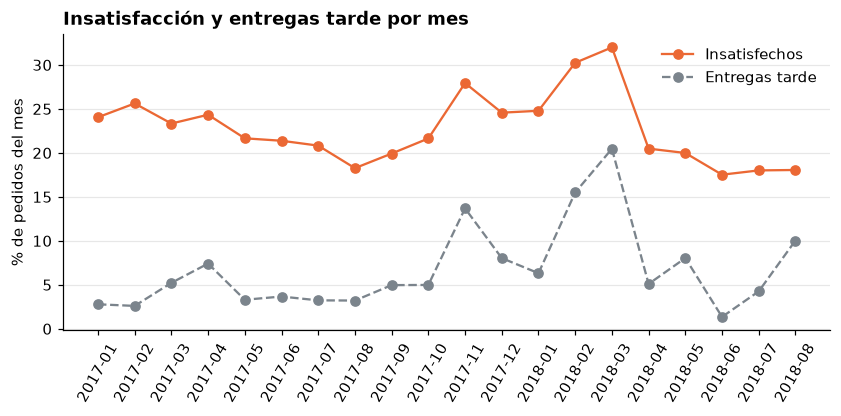

Correlación entre ambas series: 0.73


In [11]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(mensual.index, mensual["insatisfechos"] * 100, marker="o", color=NARANJA, label="Insatisfechos")
ax.plot(mensual.index, mensual["tarde"] * 100, marker="o", ls="--", color=GRIS, label="Entregas tarde")
ax.set_ylabel("% de pedidos del mes")
ax.set_title("Insatisfacción y entregas tarde por mes")
ax.tick_params(axis="x", rotation=60)
ax.legend(frameon=False)
guardar(fig, "mensual_insatisfaccion_retrasos")
plt.show()
print(f"Correlación entre ambas series: {mensual['insatisfechos'].corr(mensual['tarde']):.2f}")

### 4.2 Vendedores

In [12]:
df["varios_vendedores"] = np.where(df["n_vendedores"] > 1, "2 o más", "1")
print(df.groupby("varios_vendedores")["insatisfecho"].agg(["size", "mean"]).round(3), "\n")

despacho = df.dropna(subset=["dias_despacho_vs_limite"])
despacho_tarde = np.where(despacho["dias_despacho_vs_limite"] > 0, "Despacho tarde", "Despacho a tiempo")
despacho.groupby(despacho_tarde)["insatisfecho"].agg(["size", "mean"]).round(3)

                    size   mean
varios_vendedores              
1                  97409  0.224
2 o más             1264  0.605 



,size,mean
Despacho a tiempo,88188,0.204
Despacho tarde,8738,0.348


### 4.3 ¿Cómo recibieron el pedido los insatisfechos?

In [13]:
composicion = df.loc[df["insatisfecho"] == 1, "estado_entrega"].value_counts(normalize=True)
composicion.round(3)

estado_entrega
A tiempo        0.671
Tarde           0.222
No entregado    0.108
Name: proportion, dtype: float64

Aunque el retraso multiplica la probabilidad de insatisfacción, dos de cada tres clientes insatisfechos recibieron su pedido a tiempo. Para entender esos casos se revisan los comentarios con un conjunto de palabras clave en portugués.

### 4.4 Contenido de los comentarios

In [14]:
QUEJAS = {
    "Retraso o no recibido": r"atras|demor|prazo|n[ãa]o receb|n[ãa]o cheg|ainda n[ãa]o",
    "Pedido incompleto": r"falt|incomplet|s[óo] receb|apenas um|veio s[óo]|somente um",
    "Producto diferente": r"diferente|errad|trocad|outro produto|n[ãa]o era",
    "Producto dañado": r"quebrad|defeit|danificad|estragad|n[ãa]o funciona|amassad",
    "Calidad o falsificación": r"qualidade|falsificad|fr[áa]gil|porcaria|vagabund",
}

com = df[(df["insatisfecho"] == 1) & df["review_comment_message"].notna()].copy()
texto = com["review_comment_message"].str.lower()
a_tiempo = com["estado_entrega"] == "A tiempo"

tabla_quejas = pd.DataFrame({
    queja: {"A tiempo": texto[a_tiempo].str.contains(p).mean(),
            "Tarde o no entregado": texto[~a_tiempo].str.contains(p).mean()}
    for queja, p in QUEJAS.items()
}).T.mul(100).round(1)
print(f"Comentarios de insatisfechos: {len(com):,} ({a_tiempo.mean():.0%} con entrega a tiempo)")
tabla_quejas

Comentarios de insatisfechos: 14,377 (65% con entrega a tiempo)


,A tiempo,Tarde o no entregado
Retraso o no recibido,20.5,55.4
Pedido incompleto,12.7,4.1
Producto diferente,9.5,2.1
Producto dañado,8.1,1.3
Calidad o falsificación,7.4,1.2


Un comentario puede pertenecer a varios grupos o a ninguno, por lo que las columnas no suman 100 %.

## 5. Conclusiones

1. El incumplimiento de la fecha de entrega es el factor con mayor efecto observable: la insatisfacción pasa de 17,2 % en pedidos a tiempo a 65,4 % en pedidos tarde y 85,6 % en no entregados. Los picos mensuales de insatisfacción coinciden con los picos de entregas tarde.
2. Los pedidos con varios vendedores (60,5 %) y los despachos tardíos del vendedor (34,8 % frente a 20,4 %) también se asocian con mayor insatisfacción.
3. Sin embargo, el 67 % de los insatisfechos recibió su pedido a tiempo. En esos casos los comentarios se refieren al producto (incompleto, diferente a lo anunciado, dañado o de baja calidad), información que no está en las variables del pedido.

**Implicación para el modelado.** Se espera que un clasificador entrenado solo con variables del pedido identifique bien la insatisfacción asociada a retrasos, pero no la relacionada con el producto. Esta hipótesis se evalúa en el cuaderno 02; el cuaderno 03 incorpora el texto de las reseñas.